# Yearly Internet Sales: Bar Chart and PDF Export

**Assignment:** Use Google Colab and Python to create a bar chart of yearly sales from
`InternetSales.csv`, then save the active figure as a PDF.

This focused revision applies the Matplotlib, pandas, labels, and figure-saving methods from
*Week 07 Plotting and Visualizations.ipynb* to the assignment.

### Run in Google Colab
1. Open this notebook in Colab.
2. In the left **Files** panel, upload `InternetSales.csv` to the session folder.
3. Run the cells in order. If your CSV is elsewhere, change `DATA_PATH` below.
4. Refresh the Files panel, find `Yearly_Internet_Sales.pdf`, and use its menu to download it.

The saved outputs below were generated from the uploaded CSV. Rerun after choosing your data path.


## 1. Import packages and choose the file

`Path` avoids account-specific Google Drive paths. `pandas` reads and summarizes the data;
`matplotlib` creates and saves the chart. No additional packages are needed in a standard Colab session.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter, MultipleLocator

DATA_PATH = Path("InternetSales.csv")
PDF_PATH = Path("Yearly_Internet_Sales.pdf")


## 2. Read the required columns

Only `OrderDate` and `SalesAmount` are needed for this chart. Reading these columns avoids loading
unrelated customer details. The supplied file contains non-UTF-8 characters; `cp1252` reads it successfully.
`OrderDate` records when the sale was ordered; `YearlyIncome` is a customer attribute and must not be
used as sales revenue.


In [2]:
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Upload InternetSales.csv or update DATA_PATH: {DATA_PATH}")

sales = pd.read_csv(
    DATA_PATH,
    usecols=["OrderDate", "SalesAmount"],
    encoding="cp1252",
)

print(f"Rows read: {len(sales):,}")
print(sales.head().to_string(index=False))


Rows read: 60,398
 SalesAmount OrderDate
     3399.99 1/19/2011
     2319.99 1/18/2013
       21.98 1/18/2013
     2384.07  5/3/2013
       28.99  5/3/2013


## 3. Check the data and extract the year

`pd.to_datetime` converts the month/day/year text to dates. `.dt.year` extracts each order's calendar year.
Invalid or missing values raise an error so records cannot silently disappear from the yearly totals.


In [3]:
sales["OrderDate"] = pd.to_datetime(sales["OrderDate"], format="%m/%d/%Y", errors="raise")
sales["SalesAmount"] = pd.to_numeric(sales["SalesAmount"], errors="raise")

if sales.empty or sales["OrderDate"].isna().any() or not np.isfinite(sales["SalesAmount"]).all():
    raise ValueError("The data must contain rows with valid dates and finite sales amounts.")

sales["Year"] = sales["OrderDate"].dt.year
print(f"Date coverage: {sales['OrderDate'].min():%Y-%m-%d} to {sales['OrderDate'].max():%Y-%m-%d}")


Date coverage: 2010-12-29 to 2014-01-28


## 4. Calculate yearly sales

`groupby("Year")` collects rows from the same year. Selecting `["SalesAmount"]` and calling `.sum()`
adds their recorded sales values. `.sort_index()` keeps years in chronological order.
Each row contributes its recorded sales amount once; do not multiply by quantity again.


In [4]:
yearly_sales = sales.groupby("Year")["SalesAmount"].sum().sort_index()

print("Yearly sales (recorded SalesAmount units):")
print(yearly_sales.to_string(float_format=lambda value: f"{value:,.2f}"))

# Confirm that grouping has preserved the total.
assert np.isclose(yearly_sales.sum(), sales["SalesAmount"].sum())


Yearly sales (recorded SalesAmount units):
Year
2010       43,421.04
2011    7,075,525.93
2012    5,842,485.20
2013   16,351,550.34
2014       45,694.72


## 5. Create the bar chart and save the active figure as a PDF

`ax.bar()` draws one bar per year. Dividing by one million makes the vertical scale easier to read.
Labels show the yearly totals in millions. `plt.savefig()` saves the active figure **before** `plt.show()`;
this avoids saving an empty or different figure after display. `plt.close(fig)` releases the figure afterward.

**Interpretation:** 2010 and 2014 are partial years in the supplied data, so these bars are not directly
comparable with full-year totals. The file also contains multiple `CurrencyKey` values but no exchange-rate
or currency-definition table. The chart sums `SalesAmount` as supplied for this exercise; it does not
establish a common reporting currency or perform currency conversion. No dollar symbol is assumed.


Saved: Yearly_Internet_Sales.pdf


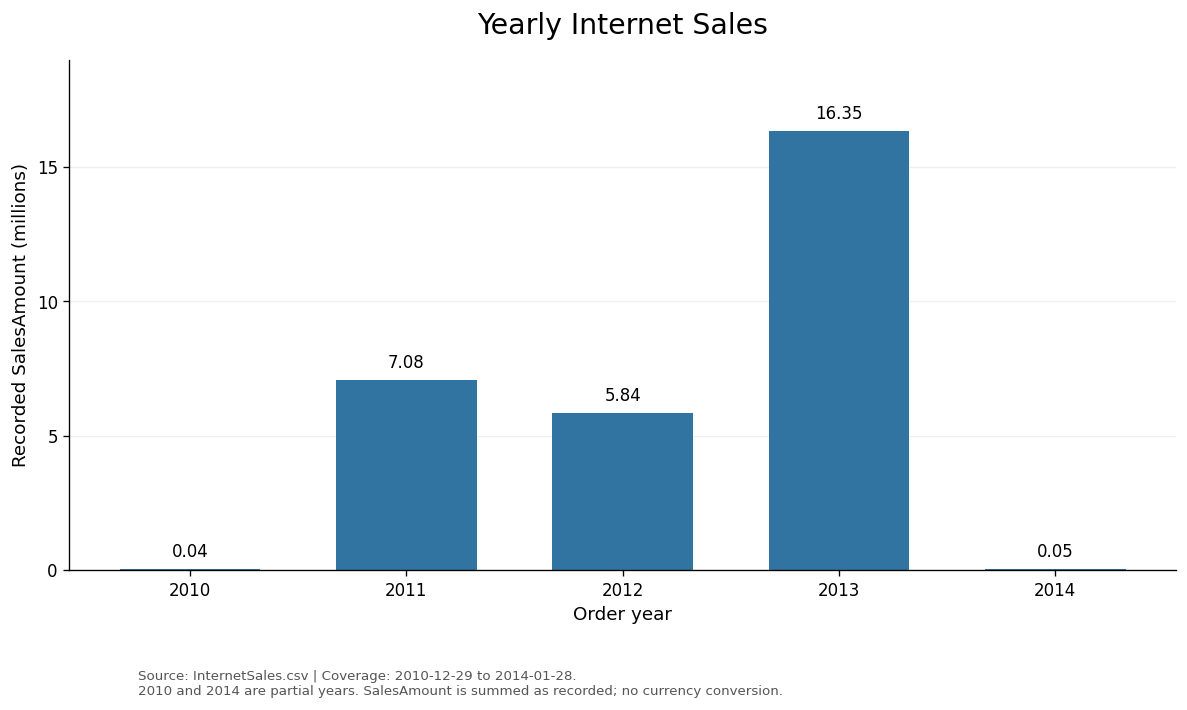

In [5]:
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    yearly_sales.index.astype(str),
    yearly_sales.to_numpy() / 1_000_000,
    color="#3274A1",
    width=0.65,
)

ax.set_title("Yearly Internet Sales", fontsize=17, pad=16)
ax.set_xlabel("Order year", fontsize=11)
ax.set_ylabel("Recorded SalesAmount (millions)", fontsize=11)
ax.yaxis.set_major_locator(MultipleLocator(5))
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.bar_label(bars, fmt="%.2f", padding=5, fontsize=10)
ax.set_ylim(0, max(yearly_sales.max() / 1_000_000 * 1.16, 1))
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)

fig.text(
    0.12, 0.025,
    "Source: InternetSales.csv | Coverage: 2010-12-29 to 2014-01-28.\n"
    "2010 and 2014 are partial years. SalesAmount is summed as recorded; no currency conversion.",
    fontsize=8, color="#555555",
)
fig.tight_layout(rect=(0, 0.10, 1, 1))

# Save the active figure in PDF format before displaying it.
plt.savefig(PDF_PATH, format="pdf", bbox_inches="tight")
print(f"Saved: {PDF_PATH}")
plt.show()
plt.close(fig)


## Improvements applied from the original lesson

- Replaced the hard-coded Drive directory with one editable CSV path.
- Removed unrelated stock-market, restaurant-tip, and macroeconomic examples to match this assignment.
- Read only the two required columns and used the actual order date and sales amount fields.
- Added date/numeric validation, chronological grouping, and a check that yearly totals reconcile.
- Built and formatted the complete figure in one cell, with clear labels and readable values.
- Saved the active figure immediately to a descriptive PDF filename before displaying it.

For a different dataset, update the date parser and coverage note to match that file before sharing the chart.
